# ML Model with actual goals

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import xgboost as xgb
import warnings

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [2]:
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)

    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))


def closed_form_solution(X, y):
    # alternative: np.dot(np.linalg.inv(np.dot(X.T, X)), np.dot(X.T, y))
    return np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))


def h(X, w):
    res = np.matmul(X, w)
    if type(res) == float:
        return res
    return res[0]


In [3]:
df_matches = pd.read_csv('matches_ac.csv', sep=';')
df_matches['bias'] = 1

noise = np.random.normal(0, 0.01, df_matches.shape[0] * 12)

for index, row in df_matches.iterrows():
    # ht
    if row["ht_curr_eff_chancediff"] == 0:
        df_matches.at[index, "ht_curr_eff_chancediff"] = noise[index]
    if row["ht_past_chancediff_combined"] == 0:
        df_matches.at[index,
                      "ht_past_chancediff_combined"] = noise[df_matches.shape[0] + index]
    if row["ht_curr_eff_chanceamount"] == 0:
        df_matches.at[index,
                      "ht_curr_eff_chanceamount"] = noise[df_matches.shape[0] * 2 + index]
    if row["ht_past_chanceamount"] == 0:
        df_matches.at[index,
                      "ht_past_chanceamount"] = noise[df_matches.shape[0] * 3 + index]
    if row["ht_fitness"] == 0:
        df_matches.at[index,
                      "ht_fitness"] = noise[df_matches.shape[0] * 4 + index]
    # at
    if row["at_curr_eff_chancediff"] == 0:
        df_matches.at[index,
                      "at_curr_eff_chancediff"] = noise[df_matches.shape[0] * 5 + index]
    if row["at_past_chancediff_combined"] == 0:
        df_matches.at[index,
                      "at_past_chancediff_combined"] = noise[df_matches.shape[0] * 6 + index]
    if row["at_curr_eff_chanceamount"] == 0:
        df_matches.at[index,
                      "at_curr_eff_chanceamount"] = noise[df_matches.shape[0] * 7 + index]
    if row["at_past_chanceamount"] == 0:
        df_matches.at[index,
                      "at_past_chanceamount"] = noise[df_matches.shape[0] * 8 + index]
    if row["at_fitness"] == 0:
        df_matches.at[index,
                      "at_fitness"] = noise[df_matches.shape[0] * 9 + index]
    # label
    if row["actual_goaldiff"] == 0:
        df_matches.at[index,
                      "actual_goaldiff"] = noise[df_matches.shape[0] * 10 + index]
    if row["actual_goalamount"] == 0:
        df_matches.at[index,
                      "actual_goalamount"] = noise[df_matches.shape[0] * 11 + index]

ga_feature_set = ["ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
                  "ht_past_chanceamount", "at_past_chanceamount", "bias"]
gd_feature_set = ["ht_curr_eff_chancediff", "at_curr_eff_chancediff", "ht_past_chancediff_combined", "at_past_chancediff_combined",
                  "ht_fitness", "at_fitness", "ht_market_value_ln_relative", "at_market_value_ln_relative", "bias"]
ga_label = ["actual_goalamount"]
gd_label = ["actual_goaldiff"]

df_matches


,country,season,matchnumber,ht_name,at_name,ht_curr_eff_chancediff,at_curr_eff_chancediff,ht_past_chancediff_combined,at_past_chancediff_combined,ht_curr_eff_chanceamount,...,at_past_chanceamount,ht_fitness,at_fitness,ht_market_value_ln_relative,at_market_value_ln_relative,ht_is_promoter,at_is_promoter,actual_goalamount,actual_goaldiff,bias
0,ENG,14,1,Queens Park Rangers,Hull,-0.000107,0.002399,0.005476,0.012542,-0.006037,...,-0.002555,-0.006322,0.003520,-0.392415,-0.348740,True,False,1,-1,1
1,ENG,14,1,Newcastle,Man City,-0.002312,0.007405,0.002748,0.001433,0.008663,...,-0.002915,0.004580,0.000216,-0.169272,1.002768,False,False,2,-2,1
2,ENG,14,1,Burnley,Chelsea,-0.004361,-0.020822,-0.009217,0.010523,-0.010237,...,0.000009,-0.000947,-0.005612,-1.140622,1.211651,True,False,4,-2,1
3,ENG,14,1,Arsenal,Crystal Palace,0.007917,0.010394,0.008286,0.007554,0.001439,...,0.000519,0.024501,-0.000151,0.917365,-0.536203,False,False,3,1,1
4,ENG,14,1,West Ham,Tottenham,0.004695,-0.000451,0.002485,0.018424,0.001249,...,-0.002009,-0.004871,-0.006536,-0.198259,0.606114,False,False,1,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Frosinone,Chievo,-4.492426,-4.452152,-3.581579,-1.943421,-2.059192,...,4.508772,-3.214579,-6.379995,-1.394930,-1.394930,True,False,0,0,1
9126,ITA,18,38,Fiorentina,CFC Genoa,1.172165,-1.286395,1.539474,-1.361842,0.407509,...,4.719298,-1.007409,1.195505,0.350310,-0.144768,False,False,0,0,1
9127,ITA,18,38,Bologna,Napoli,-0.932129,5.242267,-1.497368,5.293421,-0.446689,...,8.877193,3.155216,3.375719,-0.614771,1.070083,False,False,5,1,1
9128,ITA,18,38,Inter,Empoli,2.881676,-3.462648,2.380263,-3.058772,1.042860,...,4.403509,1.768259,2.088522,1.024225,-0.738824,False,True,3,1,1


## general weights

In [4]:

training_data = df_matches.query(f"season <= 17")

X_training_data_ga = training_data[ga_feature_set].values

X_training_data_gd = training_data[gd_feature_set].values

y_training_data_ga = training_data[ga_label].values
y_training_data_gd = training_data[gd_label].values

w_ga = closed_form_solution(X_training_data_ga, y_training_data_ga)
w_gd = closed_form_solution(X_training_data_gd, y_training_data_gd)

print("weights goalamount:\n", w_ga)
print("weights goaldiff:\n", w_gd)


weights goalamount:
 [[ 0.10011492]
 [ 0.07653586]
 [ 0.05757449]
 [-0.02643676]
 [ 2.56955303]]
weights goaldiff:
 [[ 0.05579535]
 [-0.04527673]
 [-0.02396483]
 [-0.04545011]
 [ 0.03397289]
 [-0.0183203 ]
 [ 0.61311919]
 [-0.52652414]
 [ 0.40111153]]


## weights per matchnumber

In [5]:
ga_weights, gd_weights = [], []
for i in range(1,39):
    training_data = df_matches.query(f"season <= 17 and matchnumber == {i}")

    X_training_data_ga = training_data[ga_feature_set].values
    X_training_data_gd = training_data[gd_feature_set].values
    y_training_data_ga = training_data[ga_label].values
    y_training_data_gd = training_data[gd_label].values

    ga_weights.append(closed_form_solution(
        X_training_data_ga, y_training_data_ga))
    gd_weights.append(closed_form_solution(
        X_training_data_gd, y_training_data_gd))

print("weights goalamount match no 1:\n", ga_weights[0])
print("weights goaldiff match no 1:\n", gd_weights[0])
print("weights goalamount match no 18:\n", ga_weights[17])
print("weights goaldiff match no 18:\n", gd_weights[17])


weights goalamount match no 1:
 [[21.08672031]
 [ 4.8830486 ]
 [ 0.19280095]
 [-0.10162151]
 [ 2.13500434]]
weights goaldiff match no 1:
 [[ 23.41438487]
 [ -3.181465  ]
 [  0.2579954 ]
 [ -0.08813012]
 [  0.9891285 ]
 [-21.64220066]
 [  0.45869151]
 [ -0.30217693]
 [  0.14596175]]
weights goalamount match no 18:
 [[ 0.16417797]
 [ 0.06138297]
 [-0.0428991 ]
 [ 0.06161461]
 [ 2.66531667]]
weights goaldiff match no 18:
 [[ 0.22043526]
 [-0.0818851 ]
 [ 0.05763058]
 [-0.00976169]
 [-0.04695921]
 [-0.05847834]
 [ 0.30526915]
 [-0.08849632]
 [ 0.3432038 ]]


## error general weights

In [6]:
training_data_df, test_data_df = df_matches.query(f"season < 18"), df_matches.query(f"season == 18")

ga_abs_error, gd_abs_error = 0, 0

for index, row in test_data_df.iterrows():
    X_input_ga = row[ga_feature_set].values
    X_input_gd = row[gd_feature_set].values

    ga_pred, gd_pred = h(X_input_ga, w_ga), h(X_input_gd, w_gd)
    ht_score_pred, at_score_pred = score_from_amount_and_diff(ga_pred, gd_pred)
    actual_ht_score, actual_at_score = score_from_amount_and_diff(
        row["actual_goalamount"], row["actual_goaldiff"])
    ga_abs_error += np.abs(ga_pred - row["actual_goalamount"])
    gd_abs_error += np.abs(gd_pred - row["actual_goaldiff"])

    print_formatted_pred_score(
        row["country"], row["season"], row["matchnumber"], row["ht_name"], row["at_name"], ht_score_pred, at_score_pred, actual_ht_score, actual_at_score)
    
print("Absolute error goalamount", ga_abs_error / NUM_OF_MATCHES_IN_A_SEASON)
print("Absolute error goaldiff", gd_abs_error / NUM_OF_MATCHES_IN_A_SEASON)


 ENG  18   1               Wolves              Everton       1.41:1.23 |    2:2
 ENG  18   1              Watford             Brighton       1.67:1.05 |    2:0
 ENG  18   1          Southampton              Burnley       1.73:1.03 |    0:0
 ENG  18   1            Newcastle            Tottenham       1.06:1.54 |    1:2
 ENG  18   1              Man Utd            Leicester       1.76:1.00 |    2:1
 ENG  18   1              Arsenal             Man City       1.31:1.47 |    0:2
 ENG  18   1         Huddersfield              Chelsea       0.85:1.75 |    0:3
 ENG  18   1               Fulham       Crystal Palace       1.54:1.12 |    0:2
 ENG  18   1          Bournemouth              Cardiff       1.91:0.84 |    2:0
 ENG  18   1            Liverpool             West Ham       1.98:0.89 |    4:0
 ENG  18   2            Tottenham               Fulham       2.52:0.61 |    3:1
 ENG  18   2              Everton          Southampton       1.81:0.85 |    2:1
 ENG  18   2             West Ham       

## error weights per matchnumber

In [7]:
ga_abs_error, gd_abs_error = 0, 0

for index, row in test_data_df.iterrows():
    X_input_ga = row[ga_feature_set].values
    X_input_gd = row[gd_feature_set].values
    ga_abs_error += np.abs(h(X_input_ga,
                                    ga_weights[int(row["matchnumber"])-1]) - row["actual_goalamount"])
    gd_abs_error += np.abs(h(X_input_gd,
                                    gd_weights[int(row["matchnumber"])-1]) - row["actual_goaldiff"])

print("Absolute error goalamount", ga_abs_error / NUM_OF_MATCHES_IN_A_SEASON)
print("Absolute error goaldiff", gd_abs_error / NUM_OF_MATCHES_IN_A_SEASON)


Absolute error goalamount 1.3412556126524693
Absolute error goaldiff 1.275322938517914


## Training error - general weights

In [8]:
do_a_training_error_run = False

if do_a_training_error_run:
      training_error_data = dict()
      ga_abs_training_error, gd_abs_training_error = 0,0
      prev_matchnumber = 0

      for index, row in training_data_df.iterrows():
            if row["season"] == 14 and row["matchnumber"] == 1:
                  ga_pred, gd_pred = 0,0
            else:
                  if int(row["matchnumber"]) > prev_matchnumber:
                        curr_training_data_df = training_data_df.query(f"season < {row['season']} or (season == {row['season']} and matchnumber < {row['matchnumber']})")
                        X_data_train_ga, X_data_train_gd = curr_training_data_df[ga_feature_set], curr_training_data_df[gd_feature_set]
                        y_data_train_ga, y_data_train_gd = curr_training_data_df[ga_label], curr_training_data_df[gd_label]
                        curr_ga_weight = closed_form_solution(X_data_train_ga, y_data_train_ga)
                        curr_gd_weight = closed_form_solution(X_data_train_gd, y_data_train_ga)

                  X_input_ga = row[ga_feature_set].values
                  X_input_gd = row[gd_feature_set].values

                  ga_pred, gd_pred = h(X_input_ga, curr_ga_weight), h(
                  X_input_gd, curr_gd_weight)

            ht_score_pred, at_score_pred = score_from_amount_and_diff(ga_pred, gd_pred)
            actual_ht_score, actual_at_score = score_from_amount_and_diff(
                  row["actual_goalamount"], row["actual_goaldiff"])
            ga_abs_training_error += np.abs(ga_pred - row["actual_goalamount"])
            gd_abs_training_error += np.abs(gd_pred - row["actual_goaldiff"])

            if row["country"] not in training_error_data.keys():
                  training_error_data[row["country"]] = {}
            if row["season"] not in training_error_data[row["country"]].keys():
                  training_error_data[row["country"]][row["season"]] = {}
            if row["matchnumber"] not in training_error_data[row["country"]][row["season"]].keys():
                  training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]] = {"abs_error_ga":0,"abs_error_gd":0}
            if row["country"] == "GER":
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += np.abs(ga_pred - row["actual_goalamount"]) / 9
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += np.abs(gd_pred - row["actual_goaldiff"]) / 9
            else:
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += np.abs(ga_pred - row["actual_goalamount"]) / 10
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += np.abs(gd_pred - row["actual_goaldiff"]) / 10

      print("Absolute error goalamount",
            ga_abs_training_error / (NUM_OF_MATCHES_IN_A_SEASON*4))
      print("Absolute error goaldiff", gd_abs_training_error /
            (NUM_OF_MATCHES_IN_A_SEASON*4))


In [9]:
if do_a_training_error_run:
      print("country;season_matchnumber;abs_error_ga;abs_error_gd")
      for a in training_error_data.keys():
            for b in training_error_data[a].keys():
                  for c in training_error_data[a][b].keys():
                        print(a+";"+str(b)+"_"+str(c)+";" +
                              str(training_error_data[a][b][c]["abs_error_ga"])+";"+str(training_error_data[a][b][c]["abs_error_gd"]))


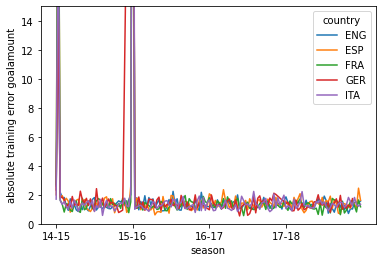

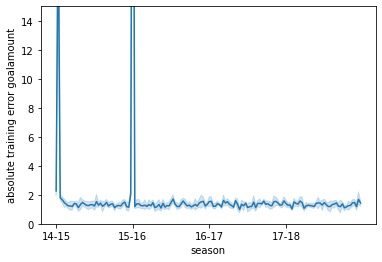

In [10]:
training_error_df = pd.read_csv('training_error_general.csv', sep=';')
sns.lineplot(data=training_error_df,
             x="season_matchnumber", y="abs_error_ga", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], ["14-15","15-16","16-17","17-18"])
plt.ylim(0, 15)
plt.xlabel("season")
plt.ylabel("absolute training error goalamount")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_ga")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 15)
plt.xlabel("season")
plt.ylabel("absolute training error goalamount")
plt.show()


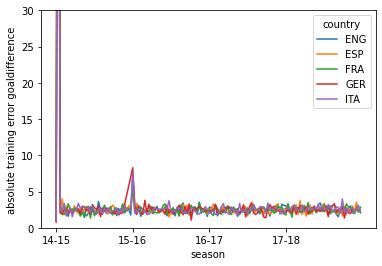

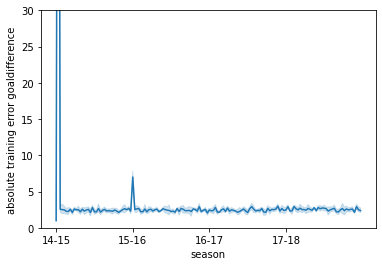

In [11]:
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 30)
plt.xlabel("season")
plt.ylabel("absolute training error goaldifference")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 30)
plt.xlabel("season")
plt.ylabel("absolute training error goaldifference")
plt.show()


## Training error - weights per matchnumber

In [12]:
do_a_training_error_run = False

if do_a_training_error_run:
    training_error_data = dict()

    curr_ga_weight_per_match, curr_gd_weight_per_match = [], []
    ga_abs_training_error, gd_abs_training_error = 0, 0

    for index, row in training_data_df.iterrows():
        if row["matchnumber"] > len(curr_ga_weight_per_match):
            curr_ga_weight_per_match.append([0, 0, 0, 0, 0])
            curr_gd_weight_per_match.append([0, 0, 0, 0, 0, 0, 0])
        curr_training_data_df = training_data_df.query(
            f"season < {row['season']} and matchnumber == {row['matchnumber']}")
        if not curr_training_data_df.empty:
            X_data_train_ga, X_data_train_gd = curr_training_data_df[ga_feature_set], curr_training_data_df[gd_feature_set]
            y_data_train_ga, y_data_train_gd = curr_training_data_df[ga_label], curr_training_data_df[gd_label]
            curr_ga_weight_per_match[int(row["matchnumber"])-1] = closed_form_solution(
                X_data_train_ga, y_data_train_ga)
            curr_gd_weight_per_match[int(row["matchnumber"])-1] = closed_form_solution(
                X_data_train_gd, y_data_train_ga)

        X_input_ga = row[ga_feature_set].values
        X_input_gd = row[gd_feature_set].values

        ga_pred, gd_pred = h(X_input_ga, curr_ga_weight_per_match[row["matchnumber"]-1]), h(
            X_input_gd, curr_gd_weight_per_match[row["matchnumber"]-1])

        ht_score_pred, at_score_pred = score_from_amount_and_diff(
            ga_pred, gd_pred)
        actual_ht_score, actual_at_score = score_from_amount_and_diff(
            row["actual_goalamount"], row["actual_goaldiff"])
        ga_abs_training_error += np.abs(
            ga_pred - row["actual_goalamount"])
        gd_abs_training_error += np.abs(
            gd_pred - row["actual_goaldiff"])

        if row["country"] not in training_error_data.keys():
                training_error_data[row["country"]] = {}
        if row["season"] not in training_error_data[row["country"]].keys():
                training_error_data[row["country"]][row["season"]] = {}
        if row["matchnumber"] not in training_error_data[row["country"]][row["season"]].keys():
                training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]] = {"abs_error_ga": 0, "abs_error_gd": 0}
        if row["country"] == "GER":
            training_error_data[row["country"]
                                ][row["season"]][row["matchnumber"]]["abs_error_ga"] += np.abs(ga_pred - row["actual_goalamount"]) / 9
            training_error_data[row["country"]
                                ][row["season"]][row["matchnumber"]]["abs_error_gd"] += np.abs(gd_pred - row["actual_goaldiff"]) / 9
        else:
            training_error_data[row["country"]
                                ][row["season"]][row["matchnumber"]]["abs_error_ga"] += np.abs(ga_pred - row["actual_goalamount"]) / 10
            training_error_data[row["country"]
                                ][row["season"]][row["matchnumber"]]["abs_error_gd"] += np.abs(gd_pred - row["actual_goaldiff"]) / 10

    print("Absolute error goalamount",
        ga_abs_training_error / (NUM_OF_MATCHES_IN_A_SEASON*4))
    print("Absolute error goaldiff", gd_abs_training_error / (NUM_OF_MATCHES_IN_A_SEASON*4))


In [13]:
if do_a_training_error_run:
      print("country;season_matchnumber;abs_error_ga;abs_error_gd")
      for a in training_error_data.keys():
            for b in training_error_data[a].keys():
                  if b != 14:
                        for c in training_error_data[a][b].keys():
                              print(a+";"+str(b)+"_"+str(c)+";" +
                                    str(training_error_data[a][b][c]["abs_error_ga"])+";"+str(training_error_data[a][b][c]["abs_error_gd"]))


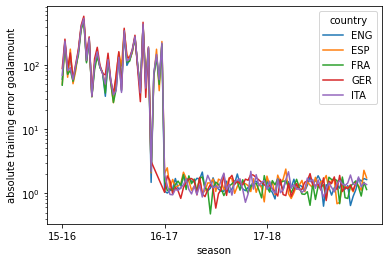

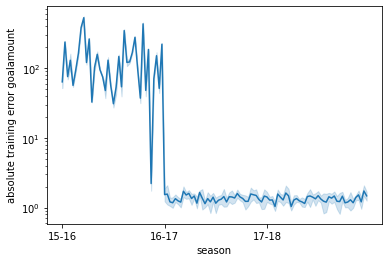

In [14]:
training_error_weights_per_matchnumber_df = pd.read_csv(
    'training_error_weights_per_match.csv', sep=';')
sns.lineplot(data=training_error_weights_per_matchnumber_df,
             x="season_matchnumber", y="abs_error_ga", hue="country")
plt.xticks(["15_1", "16_1", "17_1"], [
        "15-16", "16-17", "17-18"])
plt.yscale('log')
plt.xlabel("season")
plt.ylabel("absolute training error goalamount")
plt.show()
sns.lineplot(data=training_error_weights_per_matchnumber_df, x="season_matchnumber",
             y="abs_error_ga")
plt.xticks(["15_1", "16_1", "17_1"], [
          "15-16", "16-17", "17-18"])
plt.yscale('log')
plt.xlabel("season")
plt.ylabel("absolute training error goalamount")
plt.show()


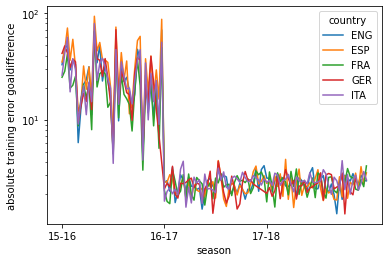

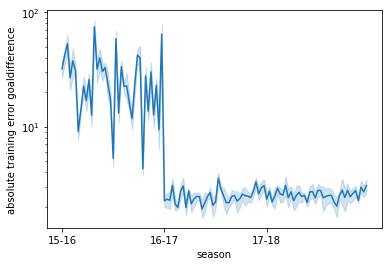

In [15]:
sns.lineplot(data=training_error_weights_per_matchnumber_df, x="season_matchnumber",
             y="abs_error_gd", hue="country")
plt.xticks([ "15_1", "16_1", "17_1"], [
            "15-16", "16-17", "17-18"])
plt.yscale('log')
plt.xlabel("season")
plt.ylabel("absolute training error goaldifference")
plt.show()

sns.lineplot(data=training_error_weights_per_matchnumber_df, x="season_matchnumber",
             y="abs_error_gd")
plt.xticks(["15_1", "16_1", "17_1"], [
           "15-16", "16-17", "17-18"])
plt.yscale('log')
plt.xlabel("season")
plt.ylabel("absolute training error goaldifference")
plt.show()


## XG Boost

In [16]:
ga_model = xgb.XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1, gamma=0,
                            importance_type='gain', learning_rate=0.1, max_delta_step=0, max_depth=3, min_child_weight=1, missing=1, 
                            n_estimators=100, n_jobs=1, nthread=None, objective='reg:squarederror', random_state=0, reg_alpha=0, 
                            reg_lambda=1, scale_pos_weight=1, seed=SEED, silent=None, subsample=1, verbosity=1)

gd_model = xgb.XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1, gamma=0,
                            importance_type='gain', learning_rate=0.1, max_delta_step=0, max_depth=3, min_child_weight=1, missing=1, 
                            n_estimators=100, n_jobs=1, nthread=None, objective='reg:squarederror', random_state=0, reg_alpha=0, 
                            reg_lambda=1, scale_pos_weight=1, seed=SEED, silent=None, subsample=1, verbosity=1)

ga_model.fit(training_data_df[ga_feature_set], training_data_df[ga_label])
gd_model.fit(training_data_df[gd_feature_set], training_data_df[gd_label])

ga_preds = ga_model.predict(test_data_df[ga_feature_set])
gd_preds = gd_model.predict(test_data_df[gd_feature_set])

# Calculate MAE
ga_abs_error, gd_abs_error = 0,0
for ga_pred, gd_pred, (index, row) in zip(ga_preds, gd_preds, test_data_df.iterrows()):
    ga_abs_error += np.abs(ga_pred - row["actual_goalamount"])
    gd_abs_error += np.abs(gd_pred - row["actual_goaldiff"])

print("XGBoost regressor MSE goalamount:",
      ga_abs_error / NUM_OF_MATCHES_IN_A_SEASON)
print("XGBoost regressor MSE goaldifference:",
      gd_abs_error / NUM_OF_MATCHES_IN_A_SEASON)


XGBoost regressor MSE goalamount: 1.317328479961132
XGBoost regressor MSE goaldifference: 1.2600499738403315


## ML Notes

- Feature Transformation (squaring,...)
- Raw Feautres and Heuer Features in correlation matrix
- leaving matchnumbers out (last 4, first 4,...)
- develop model by matchnumbers (weights for first 6, others and last 4)
- k-fold-crossvalidation